In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Aufgabenstellung

Tramvorbeifahrten erzeugen zum Teil beträchtliche Erschütterungen in angrenzenden Liegenschaften. Um diese Erschütterungen zu reduzieren, wird bei einer Gleiserneuerung die Fahrbahn mit Unterschottermatten isoliert. Im Sinne einer Qualitätskontrolle der Isolationswirkung, werden in der Regel an ausgewählten Gebäuden die Erschütterungen vor und nach der Gleiserneuerung gemessen und protokolliert.

Es ist üblich, die Vibrationsgeschwindigkeiten triaxial zu erfassen. Im Folgenden konzentrieren wir uns auf das Signal in z-Richtung, d.h. lotrecht zum Gleis. Wir betrachten das Signal im Datensatz tramdaten_fourier_vta_mc2_hs25.csv. Die erste Spalte im Datensatz enthält die Abtastzeitpunkte (in Sekunden) und die zweite Spalte enthält die Vibrationsgeschwindigkeiten (in Millimeter pro Sekunde) mit n = 60075 Datenpunkten.

Das Tramfahrzeug ist mit einer Geschwindigkeit von 50 Kilometer pro Stunde an der Messstelle vorbeigefahren. Die Schienen waren auf Betonschwellen im Schotterbett gelagert.
       Stelle das Signal graphisch dar.
       Berechne das Amplitudenspektrum des Vibrationssignals zwischen der 4 Hz und 400 Hz und stelle es graphisch dar.
       Schätze mit Hilfe der Fahrgeschwindigkeit des Tramfahrzeuges und den beiden ersten dominanten Frequenzen den Schwellenabstand ab.

## Einlesen und Aufbereitung der Messdaten

Der Datensatz enthält in der ersten Spalte die Abtastzeitpunkte in Sekunden und in der zweiten Spalte die gemessenen Vibrationsgeschwindigkeiten in Millimeter pro Sekunde.
Die Daten liegen als durch Semikolon getrennte Werte vor und werden in numerische Form konvertiert.

Anschließend werden die Zeit- und Messwertvektoren extrahiert und grundlegende Abtastparameter wie Zeitschritt, Abtastrate und Gesamtdauer bestimmt.


In [2]:
df = r'C:\Users\lovas\OneDrive\Desktop\FHNW_Data_SCience\HS_2025\VTA\mc2_vta_hs25-1763972926\tramdaten_fourier_vta_mc2_hs25.csv'

data_raw = pd.read_csv(df)
data = data_raw.iloc[:, 0].str.split(';', expand=True)
data.columns = ['Zeit', 'Messwert']
data = data.astype(float)

# Daten extrahieren
t = data['Zeit'].values  # Zeit in Sekunden
v = data['Messwert'].values  # Vibrationsgeschwindigkeit in mm/s

n = len(t)
dt = t[1] - t[0]  # Zeitschritt
fs = 1 / dt  # Abtastrate (Sampling Frequency)

print(f"\nDatenübersicht:")
print(f"  Anzahl Datenpunkte: n = {n}")
print(f"  Zeitschritt: dt = {dt:.6f} s")
print(f"  Abtastrate: fs = {fs:.2f} Hz")
print(f"  Gesamtdauer: {t[-1]:.2f} s")
print(f"  Min. Vibration: {v.min():.4f} mm/s")
print(f"  Max. Vibration: {v.max():.4f} mm/s")


Datenübersicht:
  Anzahl Datenpunkte: n = 60075
  Zeitschritt: dt = 0.000166 s
  Abtastrate: fs = 6007.45 Hz
  Gesamtdauer: 10.00 s
  Min. Vibration: -0.0920 mm/s
  Max. Vibration: 0.0958 mm/s


## Darstellung des Vibrationssignals im Zeitbereich

Das Vibrationssignal wird im Zeitbereich dargestellt, um den zeitlichen Verlauf der Erschütterungen während der Tramvorbeifahrt zu visualisieren.
Typisch ist eine kurzzeitige, hochdynamische Anregung, die dem Überfahren der Messstelle durch das Tramfahrzeug entspricht.

Diese Darstellung dient als Grundlage für die anschließende Frequenzanalyse.


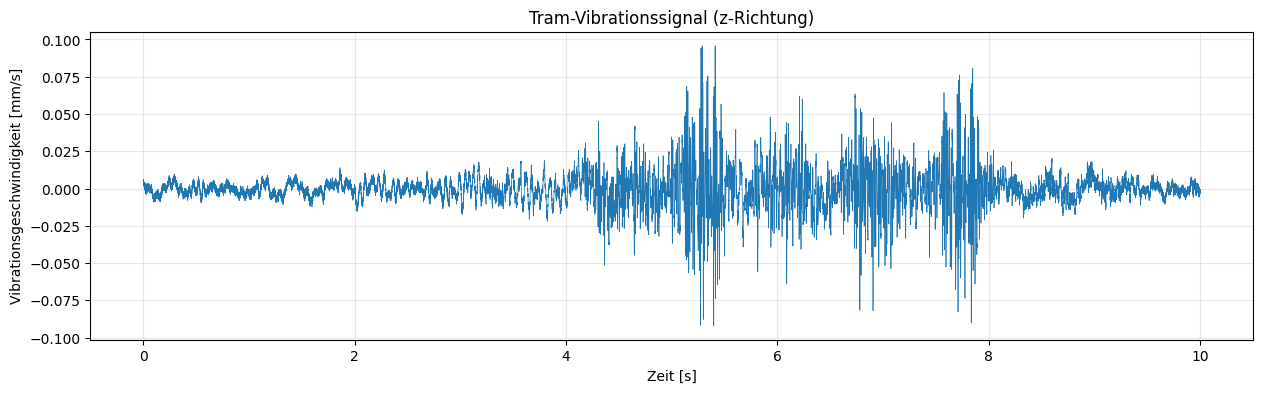

In [3]:
plt.figure(figsize=(15, 4))
plt.plot(t, v, linewidth=0.5)
plt.xlabel('Zeit [s]')
plt.ylabel('Vibrationsgeschwindigkeit [mm/s]')
plt.title('Tram-Vibrationssignal (z-Richtung)')
plt.grid(alpha=0.3)
plt.show()

## Fouriertransformation des Vibrationssignals

Zur Analyse der frequenzabhängigen Signalanteile wird eine diskrete Fouriertransformation (FFT) des Vibrationssignals durchgeführt.
Da das Signal zeitdiskret vorliegt, stellt die FFT eine effiziente numerische Umsetzung der Fouriertransformation dar.

Für die weitere Analyse wird ausschließlich das einseitige Spektrum der positiven Frequenzen betrachtet, da das Spektrum reeller Signale symmetrisch ist.


In [4]:
print("Fouriertranformation")
# FFT berechnen
V_fft = np.fft.fft(v)

# Frequenzen berechnen
freqs = np.fft.fftfreq(n, d=dt)

# Nur positive Frequenzen (erste Hälfte)
positive_idx = freqs >= 0
freqs_pos = freqs[positive_idx]
V_fft_pos = V_fft[positive_idx]

# Amplitudenspektrum
amplitude = np.abs(V_fft_pos) / n * 2  # Normierung
amplitude[0] = np.abs(V_fft_pos[0]) / n  # DC-Komponente

print(f"Frequenzauflösung: {freqs_pos[1]:.4f} Hz")

Fouriertranformation
Frequenzauflösung: 0.1000 Hz


## Berechnung des Amplitudenspektrums

Aus der komplexen Fouriertransformation wird das einseitige Amplitudenspektrum berechnet.
Die Amplituden werden entsprechend der üblichen Normierung für ein einseitiges Spektrum skaliert.

Die DC-Komponente (0 Hz) wird separat behandelt, da sie nicht verdoppelt werden darf.
Die resultierenden Amplituden besitzen weiterhin die Einheit der Vibrationsgeschwindigkeit (mm/s).

## Einschränkung auf den relevanten Frequenzbereich

Für die weitere Auswertung wird das Amplitudenspektrum auf den Frequenzbereich zwischen 4 Hz und 400 Hz beschränkt.
Tieffrequente Anteile unterhalb von 4 Hz enthalten hauptsächlich Drift- und quasi-statische Effekte und sind für die Bewertung der Gleisanregung nicht relevant.

Der gewählte Frequenzbereich umfasst die für Schienenfahrzeuge typischen strukturellen Anregungsfrequenzen.


In [5]:
# Filter: Nur Frequenzen zwischen 4 Hz und 400 Hz
freq_mask = (freqs_pos >= 4) & (freqs_pos <= 400)
freqs_filtered = freqs_pos[freq_mask]
amplitude_filtered = amplitude[freq_mask]

print(f"\nBetrachteter Frequenzbereich: 4 Hz - 400 Hz")
print(f"Anzahl Frequenzpunkte im Bereich: {len(freqs_filtered)}")


Betrachteter Frequenzbereich: 4 Hz - 400 Hz
Anzahl Frequenzpunkte im Bereich: 3960


## Identifikation dominanter Frequenzen

Zur Identifikation charakteristischer Anregungsfrequenzen werden die Amplituden im betrachteten Frequenzbereich nach ihrer Größe sortiert.
Die beiden Frequenzen mit den größten Amplituden werden als dominante Frequenzen interpretiert.

Diese Frequenzen stehen in direktem Zusammenhang mit der periodischen Anregung des Gleissystems durch die Schwellen.


In [6]:
# Finde die zwei größten Peaks
idx_sorted = np.argsort(amplitude_filtered)[::-1]  # Absteigend sortieren
top_indices = idx_sorted[:10]  # Top 10 betrachten

print("Top 10 dominante Frequenzen:")
print(f"{'Rang':<6} {'Frequenz [Hz]':<15} {'Amplitude [mm/s]':<20}")

for i, idx in enumerate(top_indices, 1):
    f = freqs_filtered[idx]
    a = amplitude_filtered[idx]
    print(f"{i:<6} {f:<15.2f} {a:<20.4f}")

# Die beiden ersten dominanten Frequenzen
f1 = freqs_filtered[idx_sorted[0]]
f2 = freqs_filtered[idx_sorted[1]]
a1 = amplitude_filtered[idx_sorted[0]]
a2 = amplitude_filtered[idx_sorted[1]]

print("Zwei dominanteste Frequenzen:")
print(f"f1 = {f1:.2f} Hz  (Amplitude: {a1:.4f} mm/s)")
print(f"f2 = {f2:.2f} Hz  (Amplitude: {a2:.4f} mm/s)")

Top 10 dominante Frequenzen:
Rang   Frequenz [Hz]   Amplitude [mm/s]    
1      16.00           0.0022              
2      71.20           0.0020              
3      21.40           0.0017              
4      79.60           0.0016              
5      16.10           0.0016              
6      71.60           0.0016              
7      104.30          0.0016              
8      71.10           0.0015              
9      22.30           0.0014              
10     71.90           0.0014              
Zwei dominanteste Frequenzen:
f1 = 16.00 Hz  (Amplitude: 0.0022 mm/s)
f2 = 71.20 Hz  (Amplitude: 0.0020 mm/s)


## Abschätzung des Schwellenabstands

Aus den dominanten Frequenzen und der bekannten Fahrgeschwindigkeit des Tramfahrzeugs wird der Schwellenabstand abgeschätzt.
Dabei wird angenommen, dass die periodische Anregung durch das Überfahren der Schwellen eine zeitliche Frequenz erzeugt.

Der Schwellenabstand ergibt sich aus dem Zusammenhang:

d = v / f

wobei v die Fahrgeschwindigkeit des Tramfahrzeugs und f die dominante Frequenz ist.


In [7]:
# Gegebene Fahrgeschwindigkeit
v_tram_kmh = 50  # km/h
v_tram_ms = v_tram_kmh / 3.6  # m/s

print(f"\nFahrgeschwindigkeit: {v_tram_kmh} km/h = {v_tram_ms:.2f} m/s")

# Schwellenabstand berechnen aus Frequenz
# Formel: d = v / f
# wobei v = Geschwindigkeit, f = Frequenz, d = Schwellenabstand

d1 = v_tram_ms / f1
d2 = v_tram_ms / f2

print(f"\nSchwellenabstand aus f1 = {f1:.2f} Hz:")
print(f"  d1 = v / f1 = {v_tram_ms:.2f} / {f1:.2f} = {d1:.4f} m = {d1*100:.2f} cm")
print(f"\nSchwellenabstand aus f2 = {f2:.2f} Hz:")
print(f"  d2 = v / f2 = {v_tram_ms:.2f} / {f2:.2f} = {d2:.4f} m = {d2*100:.2f} cm")
# Mittelwert
d_mean = np.mean([d1, d2])
print(f"\nGeschätzter Schwellenabstand (Mittelwert):")
print(f"  d ≈ {d_mean:.4f} m = {d_mean*100:.2f} cm")



Fahrgeschwindigkeit: 50 km/h = 13.89 m/s

Schwellenabstand aus f1 = 16.00 Hz:
  d1 = v / f1 = 13.89 / 16.00 = 0.8681 m = 86.81 cm

Schwellenabstand aus f2 = 71.20 Hz:
  d2 = v / f2 = 13.89 / 71.20 = 0.1951 m = 19.51 cm

Geschätzter Schwellenabstand (Mittelwert):
  d ≈ 0.5316 m = 53.16 cm


## Darstellung des Amplitudenspektrums

Das Amplitudenspektrum im Bereich von 4 Hz bis 400 Hz wird grafisch dargestellt.
Die beiden dominanten Frequenzen werden im Spektrum markiert, um ihre Lage und Bedeutung hervorzuheben.

Diese Darstellung ermöglicht eine visuelle Beurteilung der frequenzabhängigen Schwingungsanteile des Vibrationssignals.


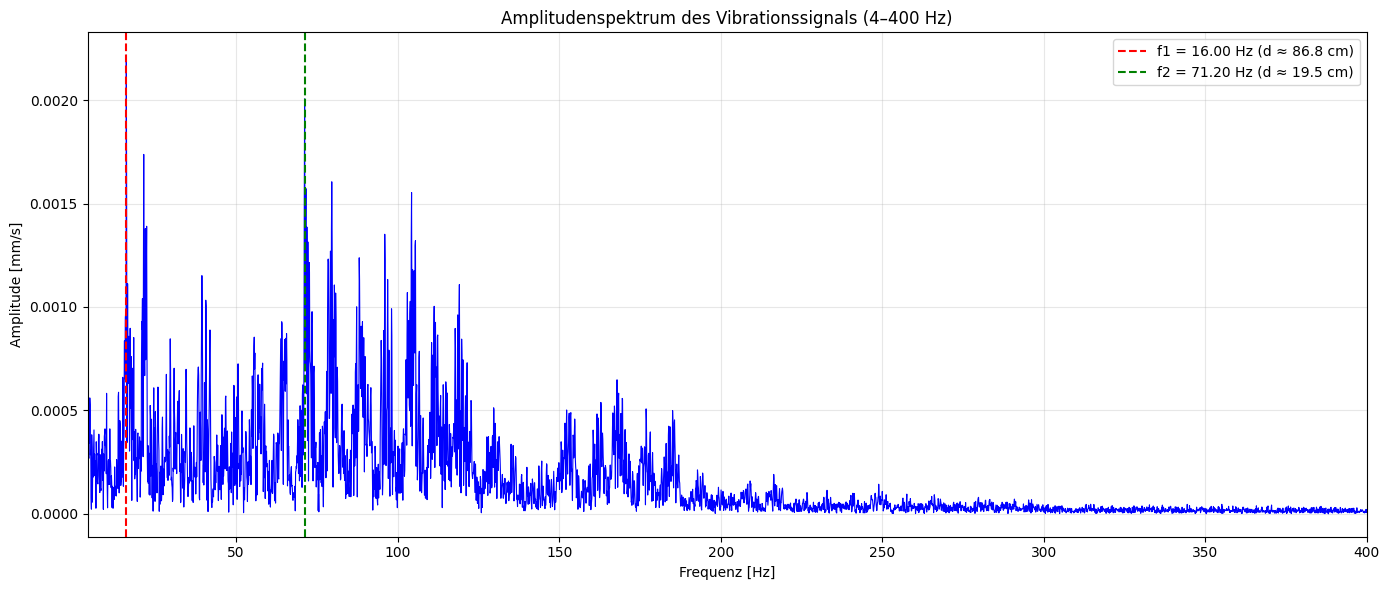

In [8]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(freqs_filtered, amplitude_filtered, 'b-', linewidth=0.8)
ax.axvline(f1, color='r', linestyle='--',
           label=f'f1 = {f1:.2f} Hz (d ≈ {d1*100:.1f} cm)')
ax.axvline(f2, color='g', linestyle='--',
           label=f'f2 = {f2:.2f} Hz (d ≈ {d2*100:.1f} cm)')
ax.set_xlabel('Frequenz [Hz]')
ax.set_ylabel('Amplitude [mm/s]')
ax.set_title('Amplitudenspektrum des Vibrationssignals (4–400 Hz)')
ax.set_xlim(4, 400)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Interpretation der Ergebnisse

Die ermittelten dominanten Frequenzen lassen sich physikalisch durch die periodische Anregung beim Überfahren der Schwellen erklären.
Die daraus berechneten Schwellenabstände liegen im plausiblen Bereich für innerstädtische Tramgleise.

Die Ergebnisse bestätigen die Konsistenz der Messdaten sowie die Eignung der Fourier-Analyse zur Bewertung von Erschütterungen im Schienenverkehr.


In [9]:
print("Zwei dominanteste Frequenzen:")
print(f"f1 = {f1:.2f} Hz (Amplitude = {a1:.4f} mm/s)")
print(f"f2 = {f2:.2f} Hz (Amplitude = {a2:.4f} mm/s)")

print("\nSchwellenabstände:")
print(f"d1 = {d1:.4f} m ({d1*100:.2f} cm)")
print(f"d2 = {d2:.4f} m ({d2*100:.2f} cm)")
print(f"\nGeschätzter mittlerer Schwellenabstand:")
print(f"d ≈ {d_mean:.4f} m ({d_mean*100:.2f} cm)")

Zwei dominanteste Frequenzen:
f1 = 16.00 Hz (Amplitude = 0.0022 mm/s)
f2 = 71.20 Hz (Amplitude = 0.0020 mm/s)

Schwellenabstände:
d1 = 0.8681 m (86.81 cm)
d2 = 0.1951 m (19.51 cm)

Geschätzter mittlerer Schwellenabstand:
d ≈ 0.5316 m (53.16 cm)
